<a href="https://colab.research.google.com/github/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting/blob/main/Chapter03_Zero_Shot_Forecasting/bonus/B12_robustness_mcb_murphy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Notebook B12 · Robustness: MCB tests and Murphy diagrams (bonus datasets)

*Hands-On Open-Source Foundation Models for Time Series Forecasting*, Chapter 3: Zero-Shot Forecasting in Practice

Notebook 11 ranked the models by their average errors. This notebook asks whether those rankings survive two
stricter tests. The **multiple comparisons with the best (MCB)** test says which models cannot be told apart, in a
statistical sense, from the best one across many forecasting tasks. **Murphy diagrams** say whether the best models
stay best under *every* scoring rule that suits a point forecast, not just under the absolute or the squared error.

The datasets are B1 and B2.

**What you will learn**

- how the MCB test turns ranks into a significance statement, and how to read an MCB plot
- what an elementary score is, and why a Murphy diagram covers every consistent loss at once
- how robust the chapter's model ranking is

| Environment and compute | |
|---|---|
| Python | 3.12 or 3.13 |
| Packages | [`requirements-dataprep.txt`](../requirements-dataprep.txt) |
| Hardware | CPU only; no GPU is needed |
| Network | none |
| Run time | about 1 minute (reads the scores cached by Notebook 11) |

**How to run this notebook**

- **Google Colab:** choose *Runtime > Run all*. Run Notebook 11 first if `results/tables/scores_per_forecast.csv`
  is missing (it is shipped with the chapter).
- **Your own computer:** the environment of Notebooks 00 to 04 (`requirements-dataprep.txt`).

In [1]:
# Setup: find this chapter's folder (on Colab: fetch it and install the packages Colab lacks)
import os
import sys
from pathlib import Path

CHAPTER = "Chapter03_Zero_Shot_Forecasting"   # this chapter's folder in the book's repository
DRIVE_COPY = ""   # Colab only, optional: path of your own copy of this folder on Google Drive
IN_COLAB = "google.colab" in sys.modules


def is_chapter(d):
    return (Path(d) / "src" / "ch03_dataprep" / "__init__.py").is_file()


if IN_COLAB:
    import importlib.metadata as md
    import shutil

    BOOK = Path("/content/book")

    def chapter_dir():
        return next((d for d in (BOOK / CHAPTER, BOOK) if is_chapter(d)), None)

    def find_in_drive(top="/content/drive/MyDrive", depth=6):   # copies of CHAPTER, shallowest first
        level = [top]
        for _ in range(depth):
            subdirs = []
            for d in level:
                try:
                    subdirs += [e.path for e in os.scandir(d) if e.is_dir() and not e.name.startswith(".")]
                except OSError:
                    pass
            hits = [d for d in subdirs if Path(d).name == CHAPTER and is_chapter(d)]
            if hits:
                return hits
            level = subdirs
        return []

    if chapter_dir() is None and not DRIVE_COPY:      # 1) clone the book's repository
        shutil.rmtree(BOOK, ignore_errors=True)
        !GIT_TERMINAL_PROMPT=0 git clone -q --depth 1 https://github.com/PacktPublishing/Hands-On-Open-Source-Foundation-Models-for-Time-Series-Forecasting /content/book
    if chapter_dir() is None:                         # 2) not on GitHub (yet): copy it from Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
        if not DRIVE_COPY:
            hits = find_in_drive()
            if len(hits) > 1:
                raise FileExistsError(f"several copies of {CHAPTER} in My Drive: {hits}. Set DRIVE_COPY to one.")
            DRIVE_COPY = hits[0] if hits else ""
        if not DRIVE_COPY or not is_chapter(DRIVE_COPY):
            raise FileNotFoundError(f"{CHAPTER} is not on GitHub or in your Google Drive. Set DRIVE_COPY to its path.")
        shutil.rmtree(BOOK, ignore_errors=True)
        shutil.copytree(DRIVE_COPY, BOOK / CHAPTER,
                        ignore=lambda d, names: [n for n in names if n.startswith(".venv") or n == "__pycache__"])
    os.chdir(chapter_dir())
    loaded = {name: md.version(name) for name in ("numpy", "pandas", "scipy", "statsmodels")}
    # Install with uv, several times faster than pip. Colab comes with uv (installed here if not). The settings point
    # uv at Colab's own Python and drop install constraints left over from building Colab's image; pip is the fallback.
    if shutil.which("uv") is None:
        %pip install -q uv
    for name in ("UV_CONSTRAINT", "UV_BUILD_CONSTRAINT", "UV_PRERELEASE"):
        os.environ.pop(name, None)
    os.environ.update(UV_PYTHON=sys.executable, UV_SYSTEM_PYTHON="1", UV_BREAK_SYSTEM_PACKAGES="1")
    !uv pip install -q -r requirements-colab.txt || {sys.executable} -m pip install -q -r requirements-colab.txt
    changed = [name for name, version in loaded.items() if md.version(name) != version]
    if changed:   # Colab had already imported the old version: restart once so Python loads the new one
        print(f"The install updated {', '.join(changed)}: restarting the session. Then choose Runtime > Run all again.")
        get_ipython().kernel.do_shutdown(True)
        raise SystemExit

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if is_chapter(p))
sys.path.insert(0, str(ROOT / "src"))
os.chdir(ROOT)
DATA, RESULTS = ROOT / "data", ROOT / "results"
INPUT = ROOT / "input_timeseries"   # the frozen datasets (CSV) and the data dictionary
print(f"chapter folder: {ROOT}  |  Python {sys.version.split()[0]}  |  Colab: {IN_COLAB}")

chapter folder: /home/user/fresh/repo/Chapter03_Zero_Shot_Forecasting  |  Python 3.12.13  |  Colab: False


In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ch03_dataprep.plotting import set_style
from ch03_zeroshot.baselines import BASELINES
from ch03_zeroshot.capabilities import ZERO_SHOT_MODELS
from ch03_zeroshot.metrics import aggregate
from ch03_zeroshot.report import load_forecasts, scores_cached
from ch03_zeroshot.robustness import dominance, dominance_share, mcb, murphy, murphy_difference, plot_mcb, plot_murphy
from ch03_zeroshot.tables import display_names

warnings.filterwarnings("ignore")
set_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", None)
DATASETS = ['B1', 'B2']
FMS = [r[0] for r in ZERO_SHOT_MODELS]
NAMES = display_names()
scores = scores_cached(ROOT, datasets=DATASETS)
FIGS = RESULTS / "figures" / "robustness_bonus"
FIGS.mkdir(parents=True, exist_ok=True)

## 1 · The MCB test

On each of $N$ forecasting tasks (here, one dataset, series, horizon and rolling window) the $M$ models are ranked
by MASE, 1 being the best. Let $\bar R_j$ be model $j$'s mean rank over the tasks. If all models were equally
accurate, the mean ranks would differ only by chance, and the largest difference between any two of them would
exceed the critical difference

$$CD = q_\alpha \sqrt{M(M+1)/(6N)}$$

only with probability $\alpha$. Here $q_\alpha$ is the upper-$\alpha$ quantile of the studentised range for $M$
groups, divided by $\sqrt 2$ (the Nemenyi test). The MCB plot draws each model's interval $\bar R_j \pm CD/2$. A
model whose interval does not overlap the best model's (shaded) is significantly worse than the best; models whose
intervals overlap it cannot be told apart from it.

The code of both tests, from [`src/ch03_zeroshot/robustness.py`](../src/ch03_zeroshot/robustness.py):

In [3]:
import numpy as np
import pandas as pd


def mcb(scores, metric="MASE", task=("dataset", "series", "horizon", "window"), alpha=0.05):
    """Mean rank and MCB interval of every model; ``scores`` has one row per model and task."""
    from scipy.stats import studentized_range

    wide = scores.pivot_table(index=list(task), columns="model", values=metric).dropna()
    ranks = wide.rank(axis=1)
    n, m = ranks.shape
    q = studentized_range.ppf(1 - alpha, m, np.inf) / np.sqrt(2)
    cd = q * np.sqrt(m * (m + 1) / (6 * n))
    out = pd.DataFrame({"mean_rank": ranks.mean()}).sort_values("mean_rank")
    out["lower"], out["upper"] = out["mean_rank"] - cd / 2, out["mean_rank"] + cd / 2
    best = out.iloc[0]
    out["worse_than_best"] = out["lower"] > best["upper"]
    out.attrs.update(cd=cd, n_tasks=n, n_models=m, alpha=alpha, metric=metric)
    return out


def friedman(scores, metric="MASE", task=("dataset", "series", "horizon", "window")):
    """Friedman test that all models rank alike over the tasks; run it before MCB on the same scores."""
    from scipy.stats import friedmanchisquare

    wide = scores.pivot_table(index=list(task), columns="model", values=metric).dropna()
    res = friedmanchisquare(*(wide[c].to_numpy() for c in wide.columns))
    return {"chi2": float(res.statistic), "df": wide.shape[1] - 1, "p": float(res.pvalue),
            "n_tasks": len(wide), "n_models": wide.shape[1]}


def plot_mcb(res, ax=None, names=None, title=None):
    """MCB plot: mean rank with interval; the best model's interval is shaded."""
    import matplotlib.pyplot as plt

    names = names or {}
    if ax is None:
        _, ax = plt.subplots(figsize=(6.5, 0.28 * len(res) + 1.2))
    y = np.arange(len(res))[::-1]
    best = res.iloc[0]
    ax.axvspan(best["lower"], best["upper"], color="#d9d9d9", zorder=0)
    for yi, (k, r) in zip(y, res.iterrows()):
        c = "#b2182b" if r["worse_than_best"] else "#2166ac"
        ax.plot([r["lower"], r["upper"]], [yi, yi], color=c, lw=1.6)
        ax.plot(r["mean_rank"], yi, "o", color=c, ms=4)
    ax.set_yticks(y)
    ax.set_yticklabels([f"{names.get(k, k)} ({r['mean_rank']:.1f})" for k, r in res.iterrows()], fontsize=8)
    ax.set_xlabel(f"mean rank on {res.attrs['metric']} (lower is better)")
    ax.set_title(title or f"MCB: {res.attrs['n_tasks']} tasks, {res.attrs['n_models']} models, "
                 f"CD = {res.attrs['cd']:.2f}", fontsize=9)
    ax.grid(axis="x", alpha=0.3)
    return ax


def elementary_scores(y, x, thetas, functional="median"):
    """Average elementary score at each theta (Ehm et al., 2016, Sec. 2).

    median (quantile level 1/2):  S_theta = 1/2 * 1{min(x, y) <= theta < max(x, y)}; integrates to MAE / 2.
    mean (expectile level 1/2):   S_theta = 1/2 * |y - theta| * 1{min(x, y) <= theta < max(x, y)};
                                  integrates to MSE / 4.
    """
    y, x = np.asarray(y, float)[:, None], np.asarray(x, float)[:, None]
    th = np.asarray(thetas, float)[None, :]
    between = (np.minimum(x, y) <= th) & (th < np.maximum(x, y))
    s = 0.5 * between if functional == "median" else 0.5 * np.abs(y - th) * between
    return s.mean(axis=0)


def murphy(forecasts, models, functional="median", n_theta=201, standardise=True):
    """Murphy curves of several models on the same forecast cases.

    forecasts: long format (model, series, horizon, window, step, y_true, y_pred). With several series of
    different scales, set standardise=True: each series is centred and scaled with its own test values.
    Returns (thetas, {model: curve}).
    """
    d = forecasts[forecasts["model"].isin(models)].copy()
    if standardise:
        g = d.groupby("series")["y_true"]
        d["y_pred"] = (d["y_pred"] - g.transform("mean")) / g.transform("std")
        d["y_true"] = (d["y_true"] - g.transform("mean")) / g.transform("std")
    wide = d.pivot_table(index=["series", "horizon", "window", "step"], columns="model", values="y_pred")
    y = d.drop_duplicates(["series", "horizon", "window", "step"]).set_index(
        ["series", "horizon", "window", "step"])["y_true"].reindex(wide.index)
    wide = wide.dropna()
    y = y.loc[wide.index]
    lo = np.nanmin([y.min(), wide.min().min()])
    hi = np.nanmax([y.max(), wide.max().max()])
    thetas = np.linspace(lo, hi, n_theta)
    return thetas, {m: elementary_scores(y, wide[m], thetas, functional) for m in models if m in wide}


def murphy_difference(forecasts, a, b, functional="median", n_theta=201, n_boot=300, block=None, seed=0):
    """Score difference a - b at each theta with a pointwise 95% band from a moving-block bootstrap
    over forecast cases (negative = a is better at that theta)."""
    thetas, curves = murphy(forecasts, [a, b], functional, n_theta)
    d = forecasts[forecasts["model"].isin([a, b])].copy()
    g = d.groupby("series")["y_true"]
    for c in ("y_pred", "y_true"):
        d[c] = (d[c] - g.transform("mean")) / g.transform("std")
    wide = d.pivot_table(index=["series", "horizon", "window", "step"], columns="model", values="y_pred").dropna()
    y = d.drop_duplicates(["series", "horizon", "window", "step"]).set_index(
        ["series", "horizon", "window", "step"])["y_true"].reindex(wide.index).to_numpy()
    th = thetas[None, :]

    def per_case(x):
        x = x[:, None]
        between = (np.minimum(x, y[:, None]) <= th) & (th < np.maximum(x, y[:, None]))
        return 0.5 * between if functional == "median" else 0.5 * np.abs(y[:, None] - th) * between

    diff = per_case(wide[a].to_numpy()) - per_case(wide[b].to_numpy())
    n = len(diff)
    block = block or max(1, int(round(n ** (1 / 3))))
    rng = np.random.default_rng(seed)
    starts = np.arange(n - block + 1)
    boots = []
    for _ in range(n_boot):
        idx = np.concatenate([np.arange(s, s + block) for s in rng.choice(starts, int(np.ceil(n / block)))])[:n]
        boots.append(diff[idx].mean(axis=0))
    boots = np.array(boots)
    return thetas, diff.mean(axis=0), np.percentile(boots, 2.5, axis=0), np.percentile(boots, 97.5, axis=0)


def plot_murphy(thetas, curves, ax=None, names=None, title="", functional="median"):
    import matplotlib.pyplot as plt

    names = names or {}
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 3.6))
    for m, c in curves.items():
        ax.plot(thetas, c, lw=1.4, label=names.get(m, m))
    ax.set_xlabel("threshold θ (standardised units)")
    ax.set_ylabel(f"mean elementary score ({functional})")
    ax.set_title(title, fontsize=9)
    ax.legend(fontsize=7, frameon=False)
    ax.grid(alpha=0.3)
    return ax


def dominance_share(thetas, curves, tol=1e-12):
    """For every pair (a, b): % of the thresholds at which the two curves differ where a scores lower than b.
    100 means a dominates b; values near 50 mean the ranking depends on the threshold."""
    keys = list(curves)
    out = pd.DataFrame(np.nan, index=keys, columns=keys)
    for a in keys:
        for b in keys:
            differ = np.abs(curves[a] - curves[b]) > tol
            if a != b and differ.any():
                out.loc[a, b] = 100 * np.mean(curves[a][differ] < curves[b][differ])
    return out


def dominance(thetas, curves, tol=1e-12):
    """For every pair (a, b): True when a's curve is never above b's (a dominates b for every consistent
    loss of this functional; Ehm et al., 2016, Corollary 1)."""
    keys = list(curves)
    return pd.DataFrame([[bool(np.all(curves[a] <= curves[b] + tol)) if a != b else np.nan for b in keys]
                         for a in keys], index=keys, columns=keys)

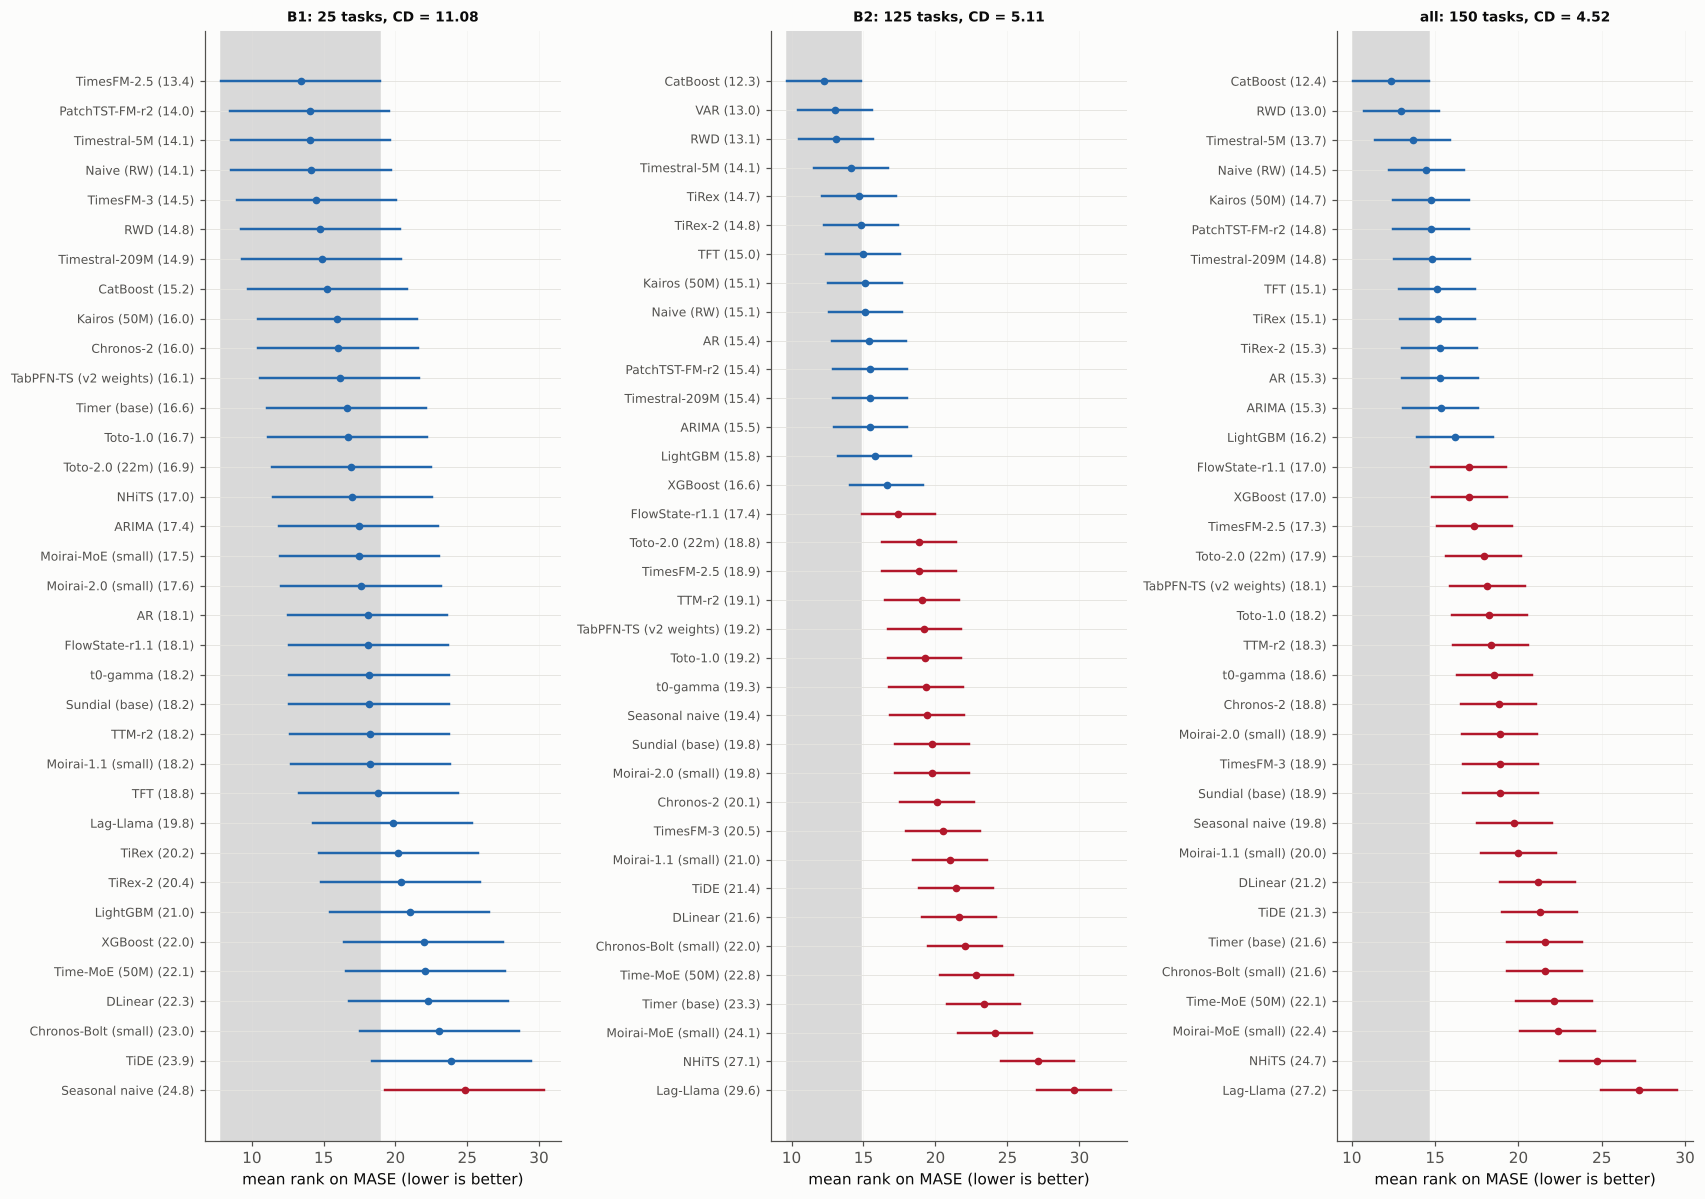

In [4]:
fig, axes = plt.subplots(1, len(DATASETS) + 1, figsize=(5.2 * (len(DATASETS) + 1), 11))
results = {}
for ax, d in zip(axes, DATASETS + ["all"]):
    s = scores if d == "all" else scores[scores["dataset"] == d]
    models = s.groupby("model")["MASE"].count()
    s = s[s["model"].isin(models[models == models.max()].index)]     # models that have every task
    results[d] = mcb(s, "MASE")
    plot_mcb(results[d], ax=ax, names=NAMES, title=f"{d}: {results[d].attrs['n_tasks']} tasks, CD = {results[d].attrs['cd']:.2f}")
plt.tight_layout()
fig.savefig(FIGS / "mcb_mase.png", dpi=150)

In [5]:
summary = pd.DataFrame({d: {"best": NAMES.get(r.index[0], r.index[0]),
                            "not worse than the best": ", ".join(NAMES.get(m, m) for m in r.index[~r["worse_than_best"]]),
                            "tasks": r.attrs["n_tasks"], "CD": round(r.attrs["cd"], 2)} for d, r in results.items()}).T
summary

,best,not worse than the best,tasks,CD
B1,TimesFM-2.5,"TimesFM-2.5, PatchTST-FM-r2, Timestral-5M, Naive (RW), TimesFM-3, RWD, Timestral-209M, CatBoost, Kairos (50M), Chronos-2, TabPFN-TS (v2 weights), Timer (base), Toto-1.0, Toto-2.0 (22m), NHiTS, ARIMA, Moirai-MoE (small), Moirai-2.0 (small), AR, FlowState-r1.1, t0-gamma, Sundial (base), TTM-r2, Moirai-1.1 (small), TFT, Lag-Llama, TiRex, TiRex-2, LightGBM, XGBoost, Time-MoE (50M), DLinear, Chronos-Bolt (small), TiDE",25,11.08
B2,CatBoost,"CatBoost, VAR, RWD, Timestral-5M, TiRex, TiRex-2, TFT, Kairos (50M), Naive (RW), AR, PatchTST-FM-r2, Timestral-209M, ARIMA, LightGBM, XGBoost",125,5.11
all,CatBoost,"CatBoost, RWD, Timestral-5M, Naive (RW), Kairos (50M), PatchTST-FM-r2, Timestral-209M, TFT, TiRex, TiRex-2, AR, ARIMA, LightGBM",150,4.52


#### The same test with another metric

If the conclusions hold with the RMSSE (squared errors) as well as with the MASE (absolute errors), they do not depend on how heavily large errors are weighted.

best by RMSSE: CatBoost | not worse than the best: CatBoost, RWD, Timestral-5M, PatchTST-FM-r2, Kairos (50M), Naive (RW), TFT, Timestral-209M, TiRex, ARIMA, TiRex-2, AR


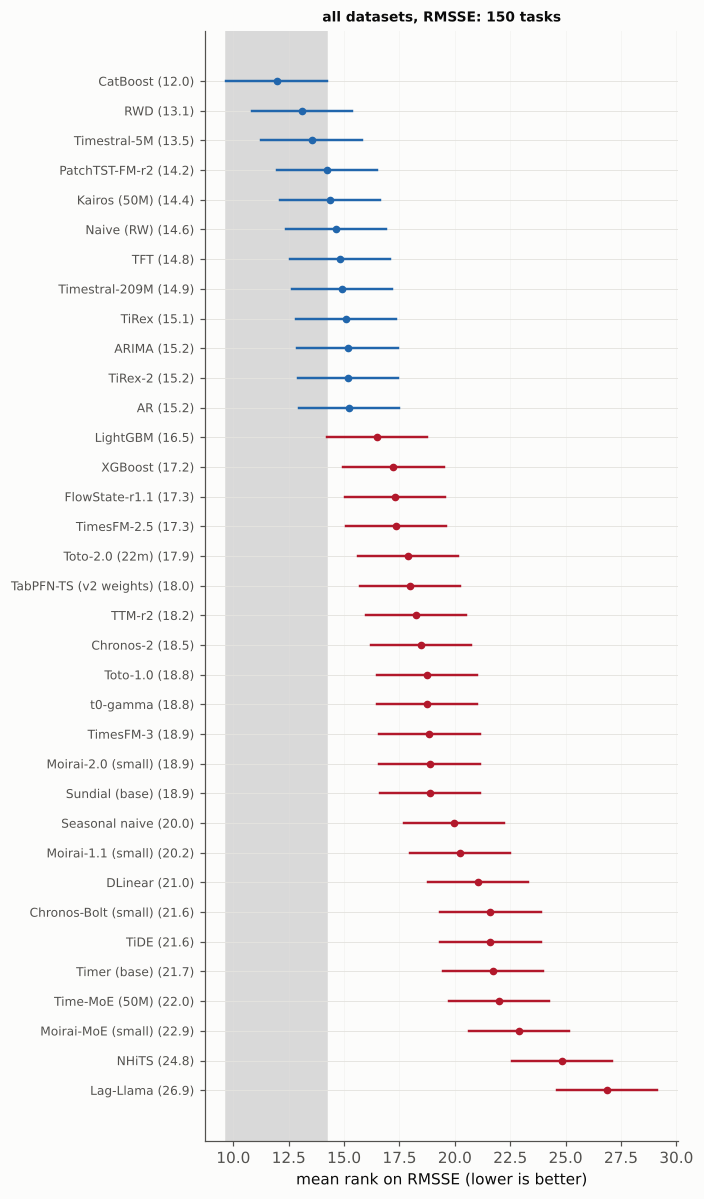

In [6]:
r_all = mcb(scores[scores["model"].isin(results["all"].index)], "RMSSE")
fig, ax = plt.subplots(figsize=(6.5, 11))
plot_mcb(r_all, ax=ax, names=NAMES, title=f"all datasets, RMSSE: {r_all.attrs['n_tasks']} tasks")
plt.tight_layout()
fig.savefig(FIGS / "mcb_rmsse.png", dpi=150)
print("best by RMSSE:", NAMES.get(r_all.index[0]), "| not worse than the best:",
      ", ".join(NAMES.get(m, m) for m in r_all.index[~r_all["worse_than_best"]]))

## 2 · Murphy diagrams

A point forecast should be evaluated with a scoring function that is *consistent* for the quantity it targets:
the absolute error for a median, the squared error for a mean. There are infinitely many consistent functions, and
they can rank two forecasts differently. A result from the theory of forecast evaluation (see References) says
that every consistent scoring function for a median (or a mean) is a weighted average of **elementary scores**
indexed by a threshold $\theta$:

$$S^{\text{median}}_ \theta(x, y) = \tfrac12\thinspace\mathrm I\lbrace\min(x,y) \le \theta < \max(x,y)\rbrace, \qquad
S^{\text{mean}}_ \theta(x, y) = \tfrac12\thinspace|y-\theta|\ \mathrm I\lbrace\min(x,y) \le \theta < \max(x,y)\rbrace.$$

Here $\mathrm I\lbrace\cdot\rbrace$ is 1 when the condition inside holds and 0 otherwise.
The first is a decision with a fixed cost of being on the wrong side of $\theta$; the second weighs that mistake by
how far the outcome lies beyond $\theta$. Integrating over $\theta$ gives back half the absolute error and a quarter of
the squared error. A **Murphy diagram** plots the average elementary score against $\theta$. If one model's curve
lies below another's everywhere, it is better for *every* consistent scoring function; if the curves cross, the
ranking depends on which thresholds matter to the user.

Most foundation models here report the median of their forecast distribution, so the median version is the natural
one; the mean version is shown too. Series are standardised with their own test values so that several series fit
on one axis.

In [7]:
top = {}
for d in DATASETS:
    s = scores[scores["dataset"] == d]
    mean_mase = s.groupby("model")["MASE"].mean()
    top[d] = list(mean_mase[mean_mase.index.isin(FMS)].nsmallest(4).index)
    best_base = mean_mase[~mean_mase.index.isin(FMS)].idxmin()
    top[d] = top[d] + [best_base]
pd.DataFrame({d: pd.Series([NAMES.get(m, m) for m in v], index=[f"FM {i}" for i in range(1, len(v))] + ["best baseline"])
              for d, v in top.items()})

,B1,B2
FM 1,PatchTST-FM-r2,Timestral-5M
FM 2,TabPFN-TS (v2 weights),Timestral-209M
FM 3,TimesFM-2.5,TiRex-2
FM 4,Timestral-5M,PatchTST-FM-r2
best baseline,Naive (RW),CatBoost


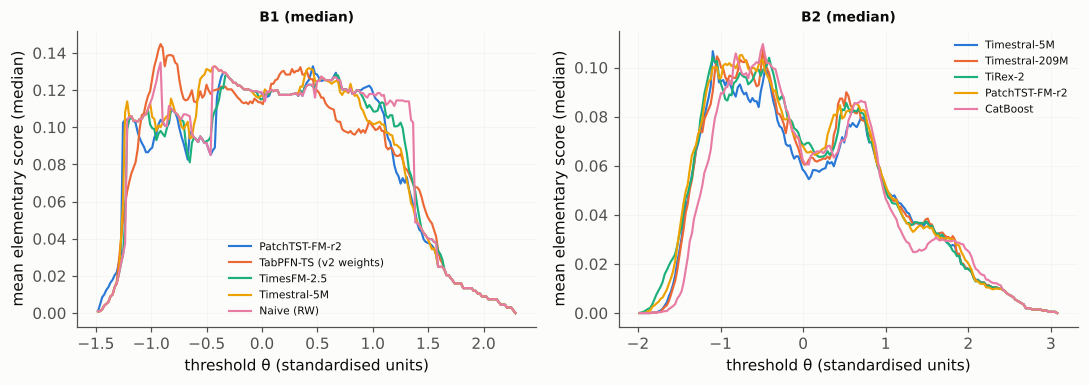

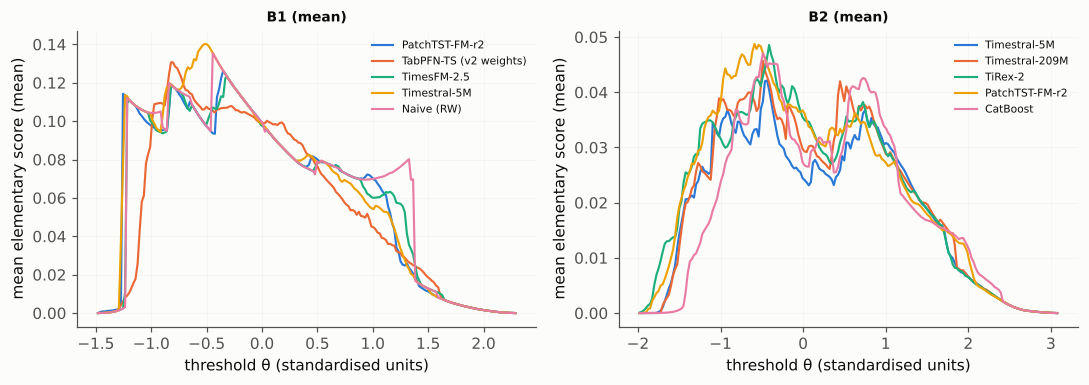

In [8]:
fc = load_forecasts(ROOT, sorted({m for v in top.values() for m in v}), DATASETS)
for functional in ["median", "mean"]:
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(5 * len(DATASETS), 3.6), squeeze=False)
    for ax, d in zip(axes[0], DATASETS):
        th, curves = murphy(fc[fc["dataset"] == d], top[d], functional=functional)
        plot_murphy(th, curves, ax=ax, names=NAMES, title=f"{d} ({functional})", functional=functional)
    plt.tight_layout()
    fig.savefig(FIGS / f"murphy_{functional}.png", dpi=150)

#### Which model dominates which?

Each number is the share (in %) of the thresholds θ at which the row model's median elementary score is lower than the column model's, counting only thresholds where the two curves differ. 100 means the row model dominates: it is at least as good for every consistent scoring function of the median. Values between 30 and 70 mean the curves cross often, so the ranking depends on which thresholds matter. The diagonal shows a dash (–): a model is not compared with itself.

In [9]:
from IPython.display import Markdown, display

for d in DATASETS:
    th, curves = murphy(fc[fc["dataset"] == d], top[d], functional="median")
    share = dominance_share(th, curves)
    share.index = share.columns = [NAMES.get(m, m) for m in share.index]
    strict = dominance(th, curves)
    pairs = [f"{NAMES.get(a, a)} over {NAMES.get(b, b)}" for a in strict.index for b in strict.columns if a != b and strict.loc[a, b] == 1]
    display(Markdown(f"**{d}** · strict dominance: {', '.join(pairs) or 'none'} (row model better than column model at this % of thresholds)"))
    display(share.style.format("{:.0f}", na_rep="–"))

**B1** · strict dominance: none (row model better than column model at this % of thresholds)

,PatchTST-FM-r2,TabPFN-TS (v2 weights),TimesFM-2.5,Timestral-5M,Naive (RW)
PatchTST-FM-r2,–,52,54,54,67
TabPFN-TS (v2 weights),48,–,49,58,52
TimesFM-2.5,46,51,–,49,78
Timestral-5M,46,42,51,–,68
Naive (RW),33,48,22,32,–


**B2** · strict dominance: none (row model better than column model at this % of thresholds)

,Timestral-5M,Timestral-209M,TiRex-2,PatchTST-FM-r2,CatBoost
Timestral-5M,–,65,71,72,59
Timestral-209M,35,–,54,64,45
TiRex-2,29,46,–,49,45
PatchTST-FM-r2,28,36,51,–,36
CatBoost,41,55,55,64,–


#### Is the gap between the two best models real?

The plot shows the difference of their median elementary scores, with a pointwise 95% band from a moving-block bootstrap over forecast cases. Where the band lies below zero, the first model is better at that threshold.

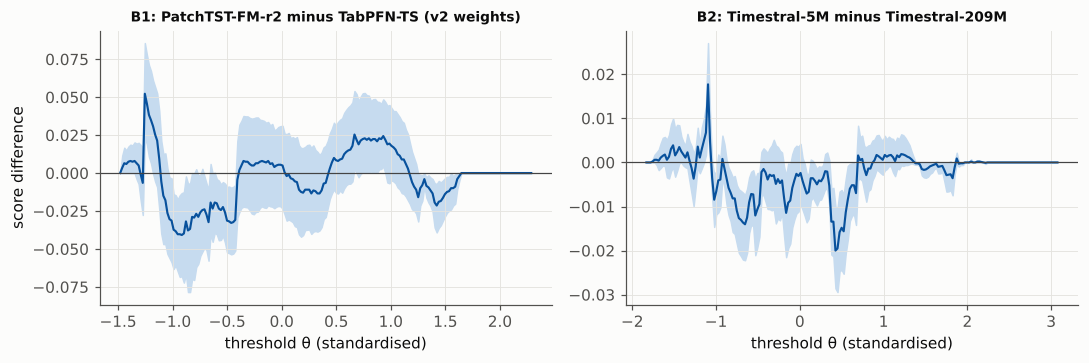

In [10]:
fig, axes = plt.subplots(1, len(DATASETS), figsize=(5 * len(DATASETS), 3.4), squeeze=False)
for ax, d in zip(axes[0], DATASETS):
    a, b = top[d][:2]
    th, diff, lo, hi = murphy_difference(fc[fc["dataset"] == d], a, b)
    ax.fill_between(th, lo, hi, color="#c6dbef")
    ax.plot(th, diff, color="#08519c")
    ax.axhline(0, color="#444444", lw=0.8)
    ax.set_title(f"{d}: {NAMES.get(a, a)} minus {NAMES.get(b, b)}", fontsize=9)
    ax.set_xlabel("threshold θ (standardised)")
axes[0][0].set_ylabel("score difference")
plt.tight_layout()
fig.savefig(FIGS / "murphy_difference.png", dpi=150)

## 3 · Key insights


- **On oil nothing can be told apart.** With 25 tasks the critical difference is 11 rank points, and 34 of 35 models
  are not significantly worse than the best (TimesFM-2.5 by mean rank); only the seasonal naive rule is.
- **On yields CatBoost leads the best group** (mean rank 12.3), followed by the VAR (13.0) and the random walk with
  drift (13.1), then Timestral-5M (14.1), TiRex and TiRex-2; 15 of 36 models are in it, NHiTS and Lag-Llama rank last.
  Over both datasets CatBoost has the best mean rank and the random walk itself is not significantly worse than it:
  on these near-random-walk series, zero-shot models bring no significant gain.
- **No Murphy curve dominates another.** On oil the curves of the four best foundation models cross constantly (each
  beats each other at 42% to 58% of the thresholds), and TimesFM-2.5 and PatchTST-FM beat the random walk at 78% and
  67% of them, but not at every threshold. On yields Timestral-5M is better than the other foundation models at 65% to 72% of
  thresholds and than CatBoost at 59%, and significantly better than Timestral-209M at 24% of them (worse at 1%).
- **RMSSE gives the same winner and the same group.** Repeated with RMSSE (squared errors), the MCB test over both
  datasets again ranks CatBoost first, and its best group holds 12 of the same 13 models (LightGBM drops out): the conclusion does not depend on
  how heavily large errors are weighted.

## References

- The MCB test and its plot (Section 1): Koning, A. J., Franses, P. H., Hibon, M., & Stekler, H. O. (2005). The M3 competition: statistical tests of the results. *International Journal of Forecasting*, 21(3), 397-409. [doi:10.1016/j.ijforecast.2004.10.003](https://doi.org/10.1016/j.ijforecast.2004.10.003)
- Critical differences of mean ranks (Section 1): Demšar, J. (2006). Statistical comparisons of classifiers over multiple data sets. *Journal of Machine Learning Research*, 7, 1-30. [jmlr.org/papers/v7/demsar06a](https://jmlr.org/papers/v7/demsar06a.html)
- The Nemenyi test (Section 1): Nemenyi, P. B. (1963). *Distribution-free multiple comparisons*. PhD thesis, Princeton University (ProQuest Dissertations & Theses No. 6406278). [ProQuest record](https://www.proquest.com/docview/302256074)
- Elementary scores and Murphy diagrams (Section 2): Ehm, W., Gneiting, T., Jordan, A., & Krüger, F. (2016). Of quantiles and expectiles: consistent scoring functions, Choquet representations and forecast rankings. *Journal of the Royal Statistical Society: Series B*, 78(3), 505-562. [doi:10.1111/rssb.12154](https://doi.org/10.1111/rssb.12154)
- Consistent scoring functions (Section 2): Gneiting, T. (2011). Making and evaluating point forecasts. *Journal of the American Statistical Association*, 106(494), 746-762. [doi:10.1198/jasa.2011.r10138](https://doi.org/10.1198/jasa.2011.r10138)
- The same MCB test in an earlier study by the authors of this book: Sengupta, S., Chakraborty, T., & Singh, S. K. (2025). Forecasting CPI inflation under economic policy and geopolitical uncertainties. *International Journal of Forecasting*, 41(3), 953-981 (Section 5.4, MCB). [doi:10.1016/j.ijforecast.2024.08.005](https://doi.org/10.1016/j.ijforecast.2024.08.005)